# Geophysical Exploration

## Proposed Exercises

In seismic refraction surveys, seismic waves can travel through the subsurface following different paths.

The main types of paths considered are:

- Direct waves
- Reflected waves
- Refracted waves

Because these waves travel different distances and velocities, they arrive at the receivers at different times.

The objective of these exercises is to analyze the recorded data and use inverse methods to estimate the properties of the subsurface.

## 1. Graphic Representation of the Data

The first step is to visualize the recorded data.

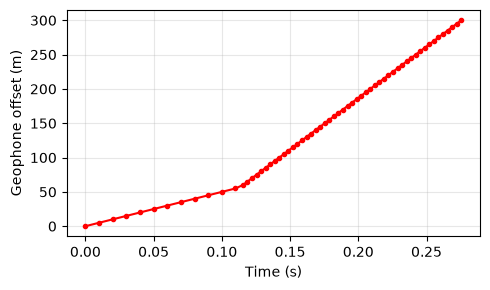

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Load the seismic data from the text file.
data = np.loadtxt('data.txt')

# Separate the geophone offset and recording time.
response = data[:, 0]
time = data[:, 1]

# Create Figure 1.
plt.figure(figsize=(5, 3))
plt.plot(time, response, marker='.', linestyle='-', color='red')

plt.xlabel('Time (s)')
plt.ylabel('Geophone offset (m)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2. Finding the velocity of the mechanical wave and the thickness of the 1rst cape

Linear regression is applied to the two propagation regimes to estimate the propagation velocities from the slopes of the fitted lines:

$$
v_1 = \text{slope}_1, \qquad v_2 = \text{slope}_2
$$

where $v_1$ and $v_2$ are the velocities in the first and second layers, respectively. The thickness of the first layer is then estimated using the intercept of the second regression:

$$
h = \frac{-b_2}{2v_2}\frac{v_2v_1}{\sqrt{v_2^2-v_1^2}}
$$

where $b_2$ is the intercept of the second fitted line. The two regression lines are finally compared with the observed data to visualize the two propagation regimes.

Velocity in the first medium: 500 m/s
Velocity in the second medium: 1500 m/s
Thickness of the first layer: 20 m


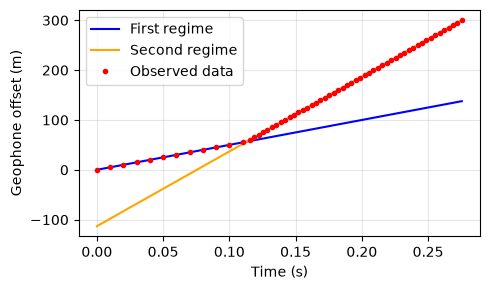

In [2]:
# Perform linear regression for the first and second propagation regime.
reg0 = linregress(time[:11], response[:11], alternative='greater')
reg1 = linregress(time[12:], response[12:], alternative='greater')

# Extract the estimated velocities from the two slopes.
vel1 = int(reg0[0])
vel2 = int(reg1[0])

# Calculate the two fitted lines.
v1 = vel1 * time + reg0[1]
v2 = vel2 * time + reg1[1]

# Estimate the thickness of the first layer.
h = int(-reg1[1] /(2 * vel2) * vel2 * vel1 /
    (vel2**2 - vel1**2)**(1/2))

# Display.
print(f'Velocity in the first medium: {vel1} m/s\n'
    f'Velocity in the second medium: {vel2} m/s\n'
    f'Thickness of the first layer: {h} m')

# Figure 2.
plt.figure(figsize=(5, 3))
plt.plot(time, v1, linestyle='-', color='blue', label='First regime')
plt.plot(time, v2, linestyle='-', color='orange', label='Second regime')
plt.plot(time, response, marker='.', linestyle='None',
         color='red', label='Observed data')
plt.xlabel('Time (s)')
plt.ylabel('Geophone offset (m)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 3. Inverse problem (linear discrete)
In the **discrete inverse problem**, we have a finite set of observed data $d$ and seek to determine the model parameters:

$$p=(D_1,D_2,D_3)$$

which define the mathematical model $f(x;p)$. The objective is to find $p$ such that $f(x;p)\approx d$.

The **residual** is defined as:

$$e=d-f(x;p)$$

The parameters are obtained by minimizing the squared $L_2$-norm of the residual:

$$\min_p \|e\|_2^2=\min_p(d-f(x;p))^T(d-f(x;p))$$

The stationary condition $\nabla_p\|e\|_2^2=0$ leads to the **normal equation**:

$$[\nabla_p f(x;p)]^T(d-f(x;p))=0$$

For a **linear forward problem**, $f(x;p)=Ap$, the least-squares solution is:

$$p=(A^TA)^{-1}A^Td=Md$$

where $M=(A^TA)^{-1}A^T$ is the **pseudoinverse matrix**.

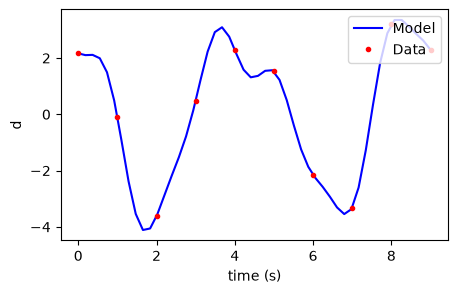

In [3]:
# Given data
d = np.array([2.1651, -0.0982, -3.6238, 0.4856,
              2.2921, 1.5247, -2.15247, -3.3124,
              3.2195, 2.2920])

# Time values
time_discrete = np.arange(len(d), dtype=float)
time_smooth = np.linspace(0, 9, 50)

def A(t):
    '''Jacobian function'''
    return np.column_stack([
        np.sin(4.488 * t + 4.189),
        np.sin(2.513 * t),
        np.sin(1.396 * t + 2.094)
    ])

# Fit parameters using the discrete data
Ad = A(time_discrete)

p = np.linalg.inv(Ad.T @ Ad) @ Ad.T @ d

# Model evaluated at smooth times
model_smooth = A(time_smooth) @ p

# Model evaluated at discrete times
model_discrete = A(time_discrete) @ p

plt.figure(figsize=(5, 3))

plt.plot(time_smooth, model_smooth,
         linestyle='-', color='blue', label='Model')
plt.plot(time_discrete, model_discrete,
         marker='.', linestyle='None', color='red', label='Data')

plt.xlabel('time (s)')
plt.ylabel('d')
plt.legend(loc='upper right')
plt.show()

### 4. Simulation with uniform accelerated movement (direct problem)
Consider a uniformly accelerated motion (UAM):

$$y(t)=y_0+v_0t-\frac{1}{2}gt^2$$

Generate a set of $n$ data points $d$ with $n>3$ by assigning specific values to the three model parameters:

$$p=(y_0,v_0,g)$$



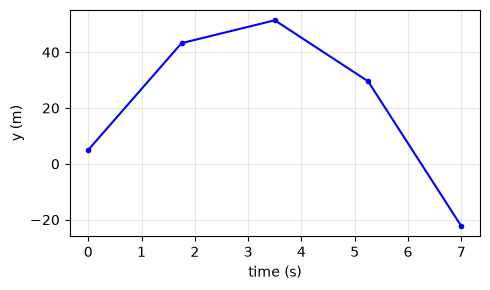

In [4]:
def y(p, t):
    '''Position function of UMA motion.'''
    y0 = p[0]
    v0 = p[1]
    g = p[2]
    
    return y0 + v0 * t - 1 / 2 * g * t**2


# Define the parameters and the observation times.
p = (5, 30.43, 9.81)
time_direct = np.linspace(0, 7, 5)

d = y(p, time_direct)

# Figure 4.
plt.figure(figsize=(5, 3))
plt.plot(time_direct, d,
         marker='.', linestyle='-', color='blue')

plt.xlabel('time (s)')
plt.ylabel('y (m)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5. Uniform accelerated movement (Inverse Problem)


The synthetic observations $d$ generated in the previous exercise are now considered measured data.

The objective is to construct the matrix $A$ and recover the parameter vector $p$ using least squares.

For the uniformly accelerated motion model:

$$
d=Ap,
$$

where:

$$
p=(y_0,v_0,g).
$$


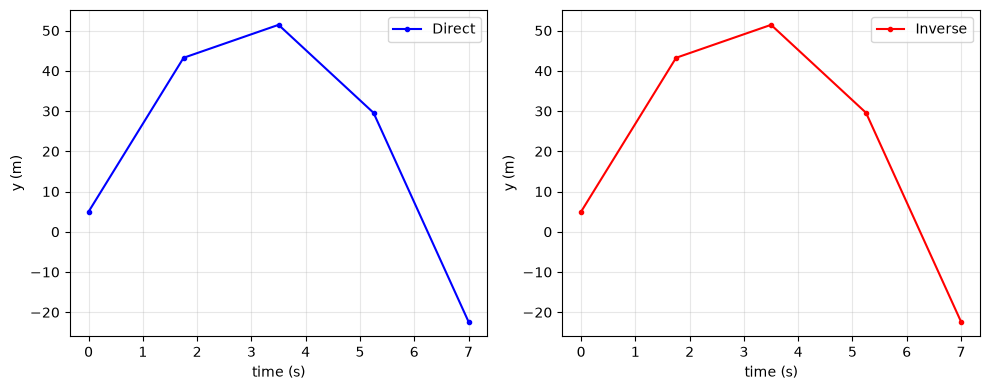

In [5]:
def jacobian(t):
    '''Jacobian funccion of the UMA position.'''
    return np.column_stack([np.ones(len(t)), t, -t**2 / 2])

# Construct the Jacobian and recover the parameter vector p.
A = jacobian(time_direct)
p = np.linalg.inv(A.T @ A) @ A.T @ d

# Figure 5. Comparison of the direct and inverse solutions.
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot(time_direct, d,
            marker='.', linestyle='-', color='blue', label='Direct')
axs[0].set_xlabel('time (s)')
axs[0].set_ylabel('y (m)')
axs[0].grid(True, alpha=0.3)
axs[0].legend()

axs[1].plot(time_direct, A @ p,
            marker='.', linestyle='-', color='red', label='Inverse')
axs[1].set_xlabel('time (s)')
axs[1].set_ylabel('y (m)')
axs[1].grid(True, alpha=0.3)
axs[1].legend()


plt.tight_layout()
plt.show()

### 6. Direct and inverse problems with Gaussian noise

In this exercise, Gaussian noise is added to the uniformly accelerated motion data.

The noisy observations are generated from the same model used previously:

$$
y(t)=y_0+v_0t-\frac{1}{2}gt^2+\text{noise}.
$$

- The noise is generated using a Gaussian distribution.
- The noisy observations are stored in $d$.
- The inverse problem is then solved using the same model structure.

### 7. Nonlinear inversion case

The signal is modeled as $d(t)=\sum_{i=1}^{3}D_i\sin(\omega_i t+\phi_i)$.  
Using $D\sin(\omega t+\phi)=A\sin(\omega t)+B\cos(\omega t)$, where $A=D\cos\phi$ and $B=D\sin\phi$, we rewrite the model as three sine-cosine terms.  
For fixed frequencies, $A_i$ and $B_i$ can be determined linearly.  
The frequencies are found iteratively by testing different values and minimizing the difference between the model and the observed data.

 data error  0.0
 accounted percentage of misfit regarding the data error  50.0
iter  5 : parameter update negligible


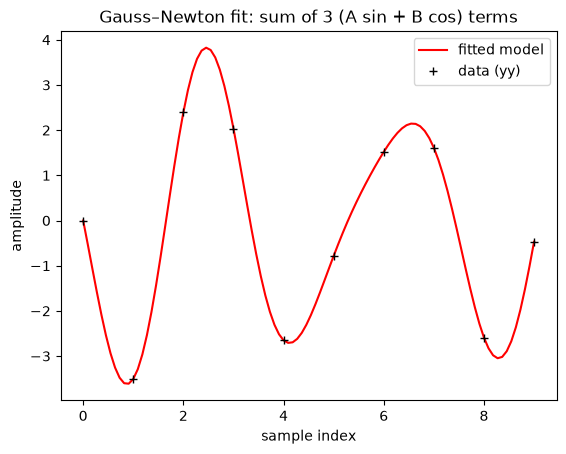

In [30]:
# Given data
d = np.array([0, -3.508, 2.393,  2.036,-2.651 ,-0.784, 1.519,1.609 ,-2.592 , -0.470])
time1 = np.arange(len(d), dtype=int)

vard = 0
noise=np.random.normal(0, vard, 10)  #  mean of 0, variance of vard and 10 data
yy = d + noise   # data with noise

A0 = np.array([-0.50, 2, -1.50, 0.87, -0.00081, -2.60])  # amplitudes
w0 = np.array([2.513, 1.795,1.496])  # periods in s
P0 = np.concatenate([A0, w0])  # parameters

# We introduce the parameters "intermax" i "eeps" for the iterative proces
norm_yy=np.linalg.norm(yy)
itermax=1000
if vard == 0:
    eeps=0.5 # misfit of 0.5% if no error in data
else:
    eeps=np.sqrt(vard)/norm_yy  # misfit

def simple_signal(p,t):
    A1, A2, A3, B1, B2, B3 = p[0:6]
    w1,w2,w3 = p[6:9]
    return (
        A1 * np.sin(w1 * t) + B1 *  np.cos(w1 * t) 
    + A2 * np.sin(w2 * t) + B2 *  np.cos(w2 * t)
    + A3 * np.sin(w3 * t) + B3 *  np.cos(w3 * t)
    )

def jac(P, t):
    """Jacobian of simple_signal"""
    A = P[0:3]
    B = P[3:6]
    w = P[6:9]
    N = len(t)
    J = np.zeros((N, 9))
    for i in range(3):
        J[:, i] = np.sin(w[i]*t)
        J[:, i + 3] = np.cos(w[i]*t)
        J[:, i + 6] = A[i] * t * np.cos(w[i]* t) - B[i] * t * np.sin(w[i]*t)
    return J

# starting model and convergence bookkeeping
P        = P0.astype(float).copy()
t        = time1.astype(float)                 # sample times
norm_d   = np.linalg.norm(yy)                  # reference norm of the data

print(' data error ', np.sqrt(vard))
print(' accounted percentage of misfit regarding the data error ', eeps*100)

converged = False
for it in range(itermax):

    y_model  = simple_signal(P, t)
    residual = yy - y_model
    norm_res = np.linalg.norm(residual)

    # Same convergence test form as the original:  norm_d / norm_yy < eeps
    if norm_d / norm_res < eeps:
        converged = True
        print('iter ', it)
        print('fit_norm', norm_d / norm_res)
        print('p_norm', np.linalg.norm(P - P0))
        print('computed model parameters (error free)')
        print(P.reshape(-1, 1))
        break

    J   = jac(P, t)
    dp  = np.linalg.solve(J.T @ J, J.T @ residual)

    if np.linalg.norm(dp) < 1e-10:             # parameter update negligible
        converged = True
        print('iter ', it, ': parameter update negligible')
        break

    P = P + dp

if not converged:
    print('NO SOLUTION: change the starting model')

t_fine = np.linspace(t.min(), t.max(), 100)
y_fine = simple_signal(P, t_fine)

plt.figure()
plt.plot(t_fine, y_fine, 'r-', label='fitted model')
plt.plot(t, yy, '+k', label='data (yy)')
plt.xlabel('sample index')
plt.ylabel('amplitude')
plt.legend()
plt.title('Gauss–Newton fit: sum of 3 (A sin + B cos) terms')
plt.show()